# Bayesian replay sampler on Mattar & Daw's maze

Mattar & Daw (2018) explain hippocampal replay as prioritized planning: each
backup is chosen by its Expected Value of Backup (EVB = Gain × Need), and
forward/reverse sequences fall out of recomputing EVB after every backup.
`notebooks/mattar_model_run.ipynb` reproduces this with the point-estimate
`PMAagent`.

This notebook runs the **Bayesian replay sampler** (`ReplaySamplerAgent`) on
the same task and protocol, so the two can be compared directly:

- **Task**: Sutton's 6×9 Dyna maze, goal at (0, 8), random start each episode,
  unit reward + N(0, 0.1) noise at the goal, deterministic moves.
- **Protocol** (M&D Methods): γ = 0.9, real actions from a softmax (β = 5)
  over Q, a planning bout of 20 backups immediately before each run and
  immediately after reward, transition model pre-explored before episode 1.
- **Beliefs**: Normal-Gamma posterior over Q, Dirichlet over T (seeded with
  the true maze, as M&D's pre-exploration), Normal-Gamma over E[r | s, a]
  (learned from real rewards, starting at 0 — the agent doesn't know where
  the reward is), and the goal known to be terminal.
- **Replay loop**: each planning step asks the sampler for the next
  trajectory (`sample_next_replay`), skips it if its EVB ≤ 0 (M&D's
  threshold), and otherwise applies it as one n-step backup
  (`execute_replay`). A trajectory of length *n* uses *n* of the bout's 20
  backups; a skipped one uses 1.

Three agents are compared:

| agent | Gain | notes |
|---|---|---|
| Bayesian, backup gain | `gain="backup"` | policy improvement from the n-step backup (M&D's Gain, with Bayesian targets) |
| Bayesian, VPI gain | `gain="vpi"` | the sampler's original priority: value of perfect information |
| PMAagent | M&D | point-estimate reference from `mattar_model_run.ipynb` |

In [1]:
import sys
sys.path.insert(0, "../..")

import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

from unc_pma.environments import NoisyGridworld
from unc_pma.bayesian_qlearning import BayesianQLearning
from unc_pma.environment_model import DirichletTransitionsModel, RewardModel, TerminalModel
from unc_pma.replay_sampling_agent import ReplaySamplerAgent, softmax_weights, plot_state_grid
from unc_pma.agents import PMAagent

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white",
                     "axes.facecolor": "white"})

# One fixed colour per agent (categorical slots 1-3), and one per replay direction.
AGENT_COLORS = {
    "Bayesian, backup gain": "#2a78d6",
    "Bayesian, VPI gain": "#eb6834",
    "PMAagent": "#1baf7a",
}
COLOR_FORWARD = "#2a78d6"
COLOR_REVERSE = "#eb6834"
COLOR_ROOT = "#8a8a85"

## Task and agents

The Bayesian agent's beliefs are built exactly as described above. Two
masks keep replay to meaningful steps: wall cells and the goal are not
replayable states (M&D also exclude the goal from planning, since nothing
follows it), and actions that bump into a wall or the grid edge are not
replayable actions.

Need is the successor-representation row of the agent's real position, with
`need_across_episodes=True`: entering the goal is followed by a reset to a
uniformly random start, matching M&D's goal→start link, so Need after reward
covers the next episode.

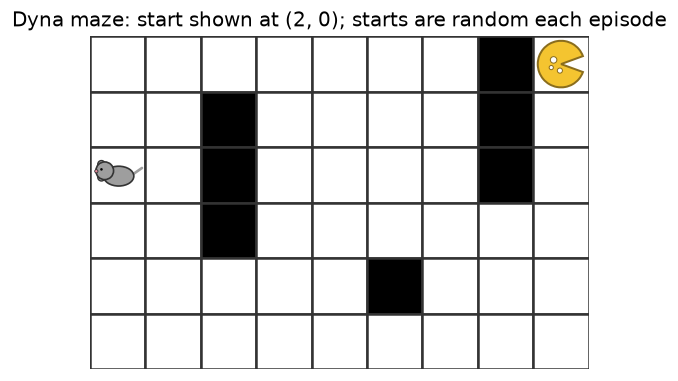

In [2]:
GAMMA = 0.9
SOFTMAX_BETA = 5.0     # real action selection, as in M&D
N_PLAN = 20            # backups per planning bout
REPLAY_TEMP = 0.01     # softmax temperature of the replay sampler (near-argmax, like M&D)
EVB_THRESHOLD = 0.0    # skip replays whose EVB doesn't clear this


def make_maze_env():
    return NoisyGridworld(
        height=6, width=9, start=(2, 0), goals={(0, 8): 1.0},
        walls={(1, 2), (2, 2), (3, 2), (0, 7), (1, 7), (2, 7), (4, 5)},
        slip_prob=0.0, reward_noise=0.1, step_cost=0.0,
        random_start=True, reward_noise_at_goal_only=True,
    )


def build_bayesian_agent(env, **sampler_kwargs):
    n_s, n_a = env.n_states, env.n_actions
    wall_states = [env._encode(*w) for w in env.walls]
    goal_states = env.goal_encoded_states

    # T seeded to the true maze (M&D's exhaustive pre-exploration), one-hot.
    transition_model = DirichletTransitionsModel(n_s, n_a)
    valid_state_actions = np.ones((n_s, n_a), dtype=bool)
    for s in range(n_s):
        if s in wall_states:
            continue
        for a in range(n_a):
            next_state, _, _ = env.deterministic_transition(s, a)
            transition_model.alpha[s, a, :] = 0.0
            transition_model.alpha[s, a, next_state] = 1.0
            valid_state_actions[s, a] = next_state != s   # no wall/edge bumps
    transition_model.mark_dead_end(wall_states)

    valid_states = np.ones(n_s, dtype=bool)
    valid_states[wall_states] = False
    valid_states[goal_states] = False

    start_distribution = np.zeros(n_s)
    start_distribution[[env._encode(*p) for p in env.valid_states]] = 1.0

    q_model = BayesianQLearning(n_s, n_a, gamma=GAMMA, mu0=0.0, lam0=1.0, alpha0=2.0, beta0=1.0)
    reward_model = RewardModel(n_s, n_a, noise="unknown", mu0=0.0, lam0=1.0, alpha0=2.0, beta0=0.1)
    terminal_model = TerminalModel(n_s, mode="known", terminal_states=goal_states)

    return ReplaySamplerAgent(
        q_model, transition_model,
        need_from_position=True, SR_policy="thomson_sampling",
        valid_states=valid_states, valid_state_actions=valid_state_actions,
        reward_model=reward_model, terminal_model=terminal_model,
        need_across_episodes=True, reset_state=start_distribution,
        **sampler_kwargs,
    )


env = make_maze_env()
fig, ax = plt.subplots(figsize=(5.4, 3.6))
env.maze_render(ax=ax)
ax.set_title("Dyna maze: start shown at (2, 0); starts are random each episode")
plt.show()

## Replay loop

`planning_bout` is the outer loop around the sampler. The sampler only
*selects* (beliefs are frozen while it chooses); `execute_replay` then
applies the chosen trajectory with the same update rule the sampler assumed
when scoring it (`update_rule="mean_only"`, η = 1: each node's posterior
mean moves to its n-step target). The next call sees the updated Q, which is
what lets one replay build on the last.

A replay's direction is read from how its tree grew: nodes added by forward
search are **forward** replay, nodes added by backward search are **reverse**
replay. A tree of length *n* therefore contributes *n* − 1 directional
events, the same count M&D's consecutive-backup classification gives a
chain of *n* backups.

In [3]:
def planning_bout(agent, state, n_plan=N_PLAN, temp=REPLAY_TEMP, threshold=EVB_THRESHOLD):
    # Returns (executed, need): executed = [(tree, strategy, evb), ...] in order.
    agent.agent_real_state = state
    used, executed, need = 0, [], None
    while used < n_plan:
        tree, strategy = agent.sample_next_replay(temp=temp)
        if need is None:
            need = agent.last_bout.need.copy()
        if agent.last_replay_evb <= threshold:
            used += 1
            continue
        agent.execute_replay(tree, strategy)
        executed.append((tree, strategy, agent.last_replay_evb))
        used += len(tree)
    return executed, need


def direction_counts(executed):
    forward = sum(strategy.count("forward") for _, strategy, _ in executed)
    reverse = sum(strategy.count("backward") for _, strategy, _ in executed)
    return forward, reverse


def value_map(q_model):
    return np.array([q_model.value(s) for s in range(q_model.n_states)])


def run_bayesian(sampler_kwargs, n_episodes, n_seeds):
    steps = np.zeros((n_seeds, n_episodes))
    counts = {phase: {d: np.zeros((n_seeds, n_episodes)) for d in ("forward", "reverse")}
              for phase in ("before", "after")}
    examples = {}
    for seed in range(n_seeds):
        np.random.seed(seed)
        env = make_maze_env()
        agent = build_bayesian_agent(env, **sampler_kwargs)
        q_model, reward_model = agent.q_model, agent.reward_model
        for ep in range(n_episodes):
            state = start_state = env.reset()
            before, before_need = planning_bout(agent, state)
            done, n = False, 0
            while not done and n < 20_000:
                probs = softmax_weights(q_model.q_means(state), temp=1.0 / SOFTMAX_BETA)
                action = int(np.random.choice(env.n_actions, p=probs))
                next_state, reward, done, _ = env.step(action)
                q_model.update(state, action, reward, next_state, done)
                reward_model.update(state, action, reward)
                state, n = next_state, n + 1
            if seed == 0 and ep == 0:
                examples["V_before_first_replay"] = value_map(q_model)
            after, after_need = planning_bout(agent, state)
            steps[seed, ep] = n
            for phase, bout in (("before", before), ("after", after)):
                f, r = direction_counts(bout)
                counts[phase]["forward"][seed, ep] = f
                counts[phase]["reverse"][seed, ep] = r
            if seed == 0:
                if ep == 0:
                    examples["after"] = (after, after_need, state)
                    examples["V_after_first_replay"] = value_map(q_model)
                f_before = direction_counts(before)[0]
                if ep > 0 and f_before > examples.get("before_forward", -1):
                    examples["before"] = (before, before_need, start_state)
                    examples["before_forward"] = f_before
                    examples["before_episode"] = ep
        if seed == 0:
            examples["V_final"] = value_map(q_model)
    return steps, counts, examples

## PMAagent reference

Same helpers and parameters as `mattar_model_run.ipynb` (exhaustive
pre-exploration with reward 0, a goal → start link in T, softmax β = 5,
α = 1, 20 planning steps before and after each run), with M&D's
consecutive-backup rule for forward/reverse.

In [4]:
PAPER_AGENT_KWARGS = dict(
    gamma=GAMMA, alpha=1.0, policy="softmax", softmax_beta=SOFTMAX_BETA, off_policy=True,
    n_plan=N_PLAN, auto_plan=False, baseline_gain=1e-10, evb_threshold=0.0,
    t_learning_rate=0.9, expand_further=True, allow_loops=False, skip_self_transitions=True,
)


def exhaustive_pre_explore(agent, env):
    wall_states = {env._encode(*w) for w in env.walls}
    goal_states = set(env.goal_encoded_states)
    for s in range(env.n_states):
        if s in goal_states or s in wall_states:
            continue
        for a in range(env.n_actions):
            next_state, _, _ = env.deterministic_transition(s, a)
            agent.model.update(s, a, 0.0, next_state)
    start_distribution = np.zeros(env.n_states)
    start_distribution[[env._encode(*p) for p in env.valid_states]] = 1.0 / len(env.valid_states)
    for g in goal_states:
        for a in range(env.n_actions):
            agent.model.set_transition(g, a, start_distribution.copy())


def classify_backups(transitions):
    labels = [None] * len(transitions)
    for i in range(len(transitions) - 1):
        cur, nxt = transitions[i], transitions[i + 1]
        if nxt.state == cur.next_state:
            labels[i] = "forward"
        elif nxt.next_state == cur.state:
            labels[i] = "reverse"
    return labels


def run_pma(n_episodes, n_seeds):
    steps = np.zeros((n_seeds, n_episodes))
    counts = {phase: {d: np.zeros((n_seeds, n_episodes)) for d in ("forward", "reverse")}
              for phase in ("before", "after")}
    for seed in range(n_seeds):
        np.random.seed(seed)
        env = make_maze_env()
        agent = PMAagent(n_states=env.n_states, n_actions=env.n_actions, **PAPER_AGENT_KWARGS)
        exhaustive_pre_explore(agent, env)
        for ep in range(n_episodes):
            state = env.reset()
            agent._current_state = state
            before = agent.plan(n_steps=N_PLAN)
            done, n = False, 0
            while not done and n < 20_000:
                action = agent.select_action(state)
                next_state, reward, done, _ = env.step(action)
                agent.update(state, action, reward, next_state, done)
                state, n = next_state, n + 1
            agent._current_state = state
            after = agent.plan(n_steps=N_PLAN)
            steps[seed, ep] = n
            for phase, bout in (("before", before), ("after", after)):
                labels = classify_backups([traj[-1] for traj, _, _ in bout])
                counts[phase]["forward"][seed, ep] = labels.count("forward")
                counts[phase]["reverse"][seed, ep] = labels.count("reverse")
    return steps, counts

## Run

8 seeds × 50 episodes per agent. The VPI-gain agent is the slowest (its
default path keeps the original per-pair VPI loop); expect several minutes
in total.

In [5]:
N_EPISODES, N_SEEDS = 50, 8
results = {}

t0 = time.time()
steps, counts, examples_backup = run_bayesian(dict(gain="backup"), N_EPISODES, N_SEEDS)
results["Bayesian, backup gain"] = (steps, counts)
print(f"Bayesian, backup gain: {time.time() - t0:.0f}s")

t0 = time.time()
steps, counts, examples_vpi = run_bayesian(dict(gain="vpi"), N_EPISODES, N_SEEDS)
results["Bayesian, VPI gain"] = (steps, counts)
print(f"Bayesian, VPI gain:    {time.time() - t0:.0f}s")

t0 = time.time()
results["PMAagent"] = run_pma(N_EPISODES, N_SEEDS)
print(f"PMAagent:              {time.time() - t0:.0f}s")

print()
print(f"{'agent':24s} {'ep 1':>7s} {'ep 2-5':>7s} {'ep 41-50':>9s}   (mean steps to reward)")
for name, (steps, _) in results.items():
    print(f"{name:24s} {steps[:, 0].mean():7.0f} {steps[:, 1:5].mean():7.0f} {steps[:, -10:].mean():9.1f}")

Bayesian, backup gain: 182s


Bayesian, VPI gain:    408s


PMAagent:              20s

agent                       ep 1  ep 2-5  ep 41-50   (mean steps to reward)
Bayesian, backup gain        511      35      49.4
Bayesian, VPI gain           928     502      44.0
PMAagent                     733      14      63.8


## Learning speed

M&D's Fig. 1e claim: prioritized replay makes steps-to-reward fall sharply
once the reward has been found. Episode 1 is the same random walk for every
agent that hasn't replayed anything useful yet (no reward is known).

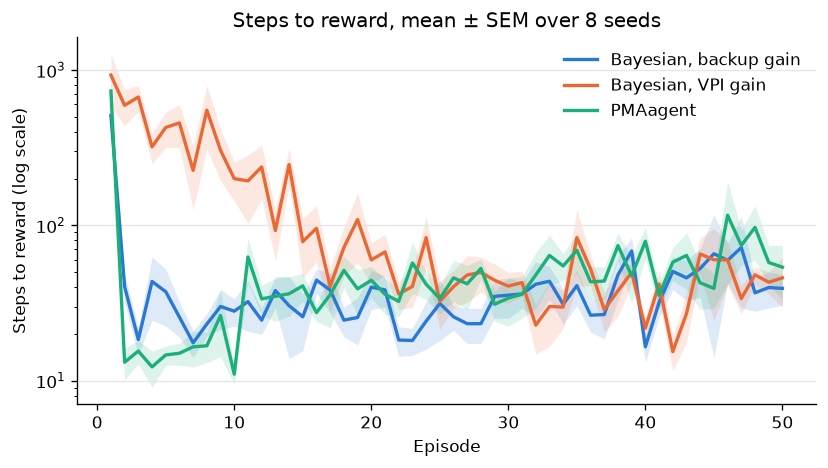

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
episodes = np.arange(1, N_EPISODES + 1)
for name, (steps, _) in results.items():
    mean = steps.mean(axis=0)
    sem = steps.std(axis=0) / np.sqrt(steps.shape[0])
    ax.plot(episodes, mean, color=AGENT_COLORS[name], lw=2, label=name)
    ax.fill_between(episodes, np.maximum(mean - sem, 1), mean + sem, color=AGENT_COLORS[name], alpha=0.15, lw=0)
ax.set_yscale("log")
ax.set_xlabel("Episode")
ax.set_ylabel("Steps to reward (log scale)")
ax.set_title(f"Steps to reward, mean ± SEM over {N_SEEDS} seeds")
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Replay direction before vs. after a run (M&D Fig. 3a)

M&D's central replay result: **forward** replay concentrates *before* a run
(Need is highest just ahead of the agent), **reverse** replay *after*
reward (Gain is highest at the predecessors of the state whose value just
changed). Bars are directional events per bout, averaged over all episodes
and seeds.

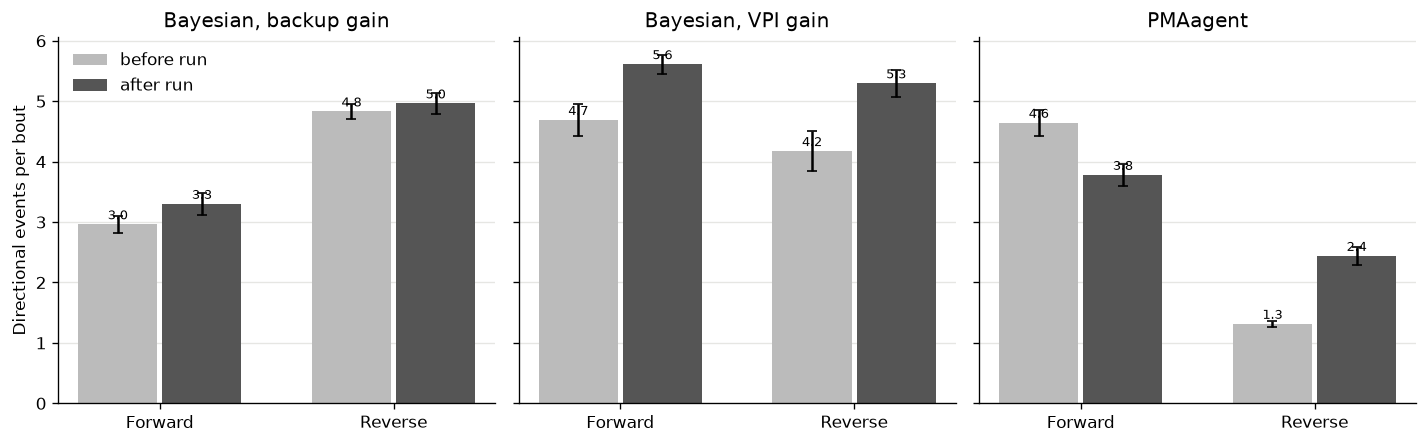

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
x = np.arange(2)
width = 0.36
for ax, (name, (_, counts)) in zip(axes, results.items()):
    for offset, phase, color in ((-width / 2, "before", "#bbbbbb"), (width / 2, "after", "#555555")):
        vals = [counts[phase][d].mean() for d in ("forward", "reverse")]
        errs = [counts[phase][d].mean(axis=1).std() / np.sqrt(N_SEEDS) for d in ("forward", "reverse")]
        bars = ax.bar(x + offset, vals, width * 0.94, yerr=errs, capsize=3, color=color,
                      label=f"{phase} run")
        for bar, v in zip(bars, vals):
            ax.annotate(f"{v:.1f}", (bar.get_x() + bar.get_width() / 2, v), xytext=(0, 3),
                        textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(x, ["Forward", "Reverse"])
    ax.set_title(name)
    ax.grid(axis="y", color="#e6e6e3", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Directional events per bout")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

### How the pattern evolves over learning

The averages above pool every episode. Splitting by episode shows *when*
each kind of replay happens: reverse replay right after the reward is first
found, and whether forward replay appears before runs once values have
settled. Curves are smoothed with a 5-episode moving average.

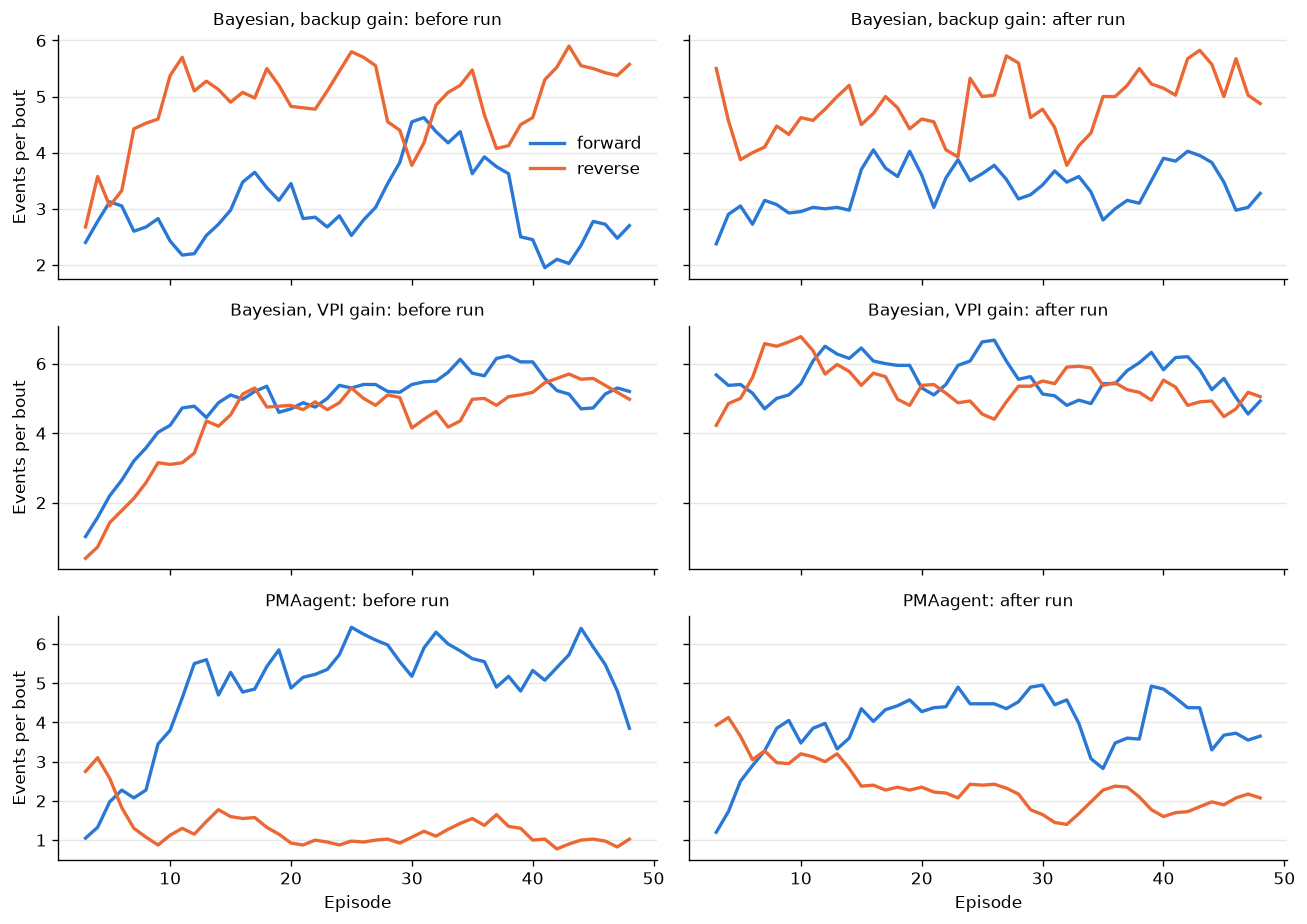

In [8]:
def smooth(y, k=5):
    return np.convolve(y, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(len(results), 2, figsize=(11, 2.6 * len(results)), sharex=True, sharey="row")
for row, (name, (_, counts)) in enumerate(results.items()):
    for col, phase in enumerate(("before", "after")):
        ax = axes[row, col]
        for direction, color in (("forward", COLOR_FORWARD), ("reverse", COLOR_REVERSE)):
            y = smooth(counts[phase][direction].mean(axis=0))
            ax.plot(np.arange(len(y)) + 3, y, color=color, lw=2, label=direction)
        ax.set_title(f"{name}: {phase} run", fontsize=10)
        ax.grid(axis="y", color="#e6e6e3", lw=0.8)
    axes[row, 0].set_ylabel("Events per bout")
axes[0, 0].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Episode")
plt.tight_layout()
plt.show()

## Example bouts (M&D Fig. 2 style)

Each replayed node is drawn as an arrow from its state along its action,
coloured by how its tree grew (forward, reverse, or a lone root), and
numbered by the order in which trees were executed in the bout. The
background is Need from the agent's position (the mouse).

**After the first reward**: the backup-gain agent should sweep backward from
the goal. **Before a run**: the before-run bout from seed 0 with the most
forward events.

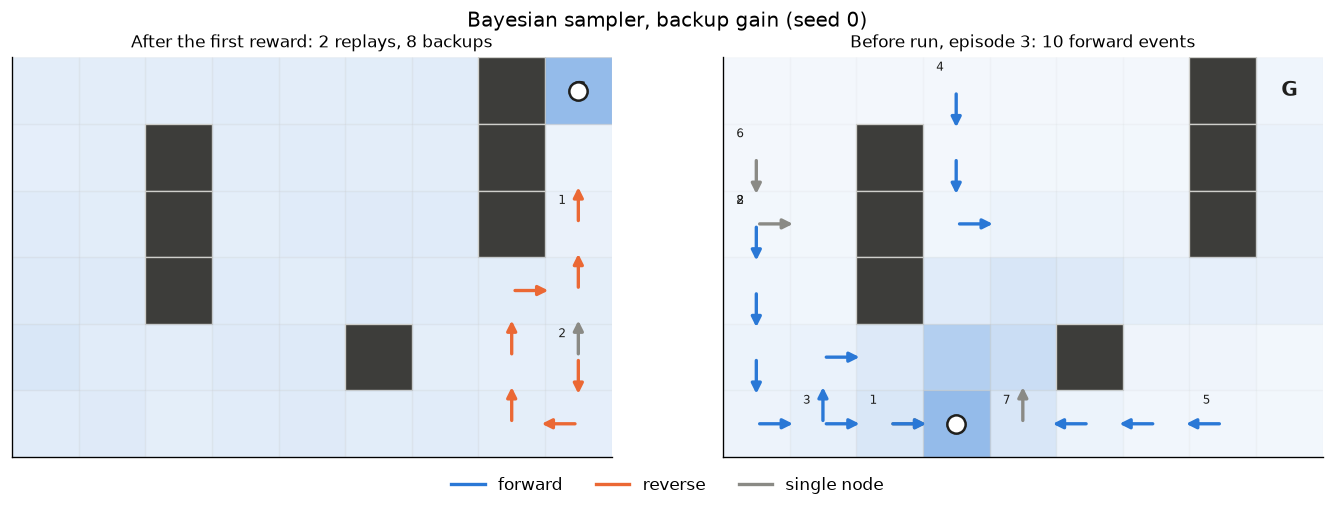

In [9]:
def plot_bout(env, executed, need, agent_state, title, ax):
    nonwall = [s for s in range(env.n_states) if env._decode(s) not in env.walls]
    need_max = max(need[s] for s in nonwall) or 1.0
    for s in range(env.n_states):
        r, c = env._decode(s)
        if (r, c) in env.walls:
            face, alpha = "#3d3d3a", 1.0
        else:
            face, alpha = "#2a78d6", 0.05 + 0.45 * need[s] / need_max
        ax.add_patch(plt.Rectangle((c - 0.5, -r - 0.5), 1, 1, facecolor=face, alpha=alpha,
                                   edgecolor="#cfcfcb", lw=0.8))
    for (gr, gc) in env.goals:
        ax.text(gc, -gr, "G", ha="center", va="center", fontsize=12, fontweight="bold", color="#1f1f1d")
    if agent_state is not None:
        ar, ac = env._decode(agent_state)
        ax.plot(ac, -ar, "o", ms=11, mfc="white", mec="#1f1f1d", mew=1.5, zorder=5)

    for k, (tree, strategy, _) in enumerate(executed, start=1):
        direction = "reverse" if "backward" in strategy else ("forward" if "forward" in strategy else "root")
        color = {"forward": COLOR_FORWARD, "reverse": COLOR_REVERSE, "root": COLOR_ROOT}[direction]
        for node in tree:
            r, c = env._decode(node.state)
            nr, nc = env._decode(env.deterministic_transition(node.state, node.action)[0])
            ax.annotate("", xy=(c + 0.6 * (nc - c), -r - 0.6 * (nr - r)), xytext=(c, -r),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=12), zorder=4)
        r, c = env._decode(tree[0].state)
        ax.text(c - 0.3, -r + 0.3, str(k), fontsize=7, color="#1f1f1d", zorder=6)
    ax.set_xlim(-0.5, env.width - 0.5)
    ax.set_ylim(-env.height + 0.5, 0.5)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10)


env = make_maze_env()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
executed, need, agent_state = examples_backup["after"]
plot_bout(env, executed, need, agent_state,
          f"After the first reward: {len(executed)} replays, "
          f"{sum(len(t) for t, _, _ in executed)} backups", axes[0])
executed, need, agent_state = examples_backup["before"]
plot_bout(env, executed, need, agent_state,
          f"Before run, episode {examples_backup['before_episode'] + 1}: "
          f"{examples_backup['before_forward']} forward events", axes[1])
handles = [plt.Line2D([], [], color=c, lw=2, label=l) for l, c in
           (("forward", COLOR_FORWARD), ("reverse", COLOR_REVERSE), ("single node", COLOR_ROOT))]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Bayesian sampler, backup gain (seed 0)")
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## What the first reverse sweep does to values

V(s) = max_a E[Q(s, a)] for seed 0 of the backup-gain agent: after the first
real episode (only the transition into the goal has been learned from
experience), after the replay bout that follows it, and after 50 episodes.

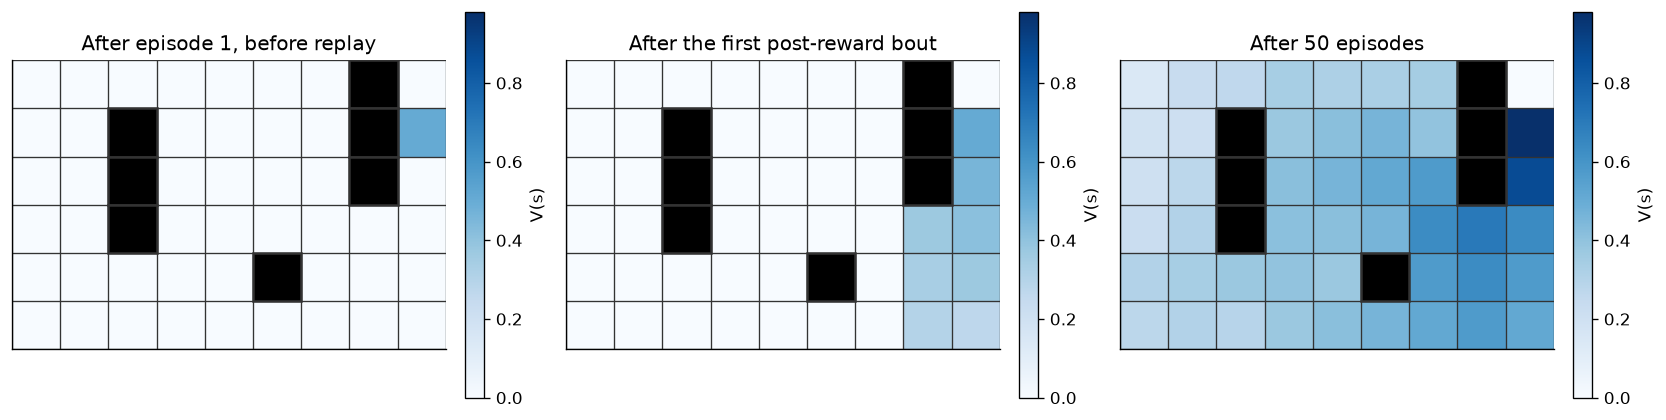

In [10]:
env = make_maze_env()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
panels = (("V_before_first_replay", "After episode 1, before replay"),
          ("V_after_first_replay", "After the first post-reward bout"),
          ("V_final", f"After {N_EPISODES} episodes"))
vmax = max(examples_backup[k].max() for k, _ in panels)
for ax, (key, title) in zip(axes, panels):
    plot_state_grid(examples_backup[key], env.height, env.width, title=title, cbar_label="V(s)",
                    walls=env.walls, ax=ax, cmap="Blues", norm=Normalize(0.0, vmax))
plt.tight_layout()
plt.show()


## Summary

**What reproduces**

- **Learning speed.** With backup gain, steps to reward fall from ~510 in
  episode 1 to ~35 in episodes 2–5, close to PMAagent (~14). The first
  post-reward bout is a reverse sweep from the goal (2 replays, 8 backups),
  which puts value on the whole right-hand corridor at once (value maps
  above), because each replay is a single n-step backup. Both agents settle
  around 40–60 steps, which is about what softmax β = 5 allows on values of
  this scale.
- **Reverse replay after reward.** Right after the first reward, replay is
  reverse, as in M&D.

**What doesn't**

- **Forward replay before runs.** PMAagent shows M&D's Fig. 3a pattern
  (before: 4.6 forward vs 1.3 reverse events per bout; reverse rises after
  runs). The backup-gain sampler does not: reverse dominates both before
  (4.8 vs 3.0) and after (5.0 vs 3.3) runs, throughout learning.
  In M&D, forward replay before a run is what EVB does once Gain has
  flattened: a tiny floor (`baseline_gain`) leaves Need alone to rank
  backups, and argmax then follows Need forward from the agent. Here two
  things differ. (1) Gain doesn't flatten: real experience updates Q with
  the Normal-Gamma step 1/(λ+1), so Q keeps lagging what the model implies
  and there is always gain to propagate, which the backward search does
  best. (2) Without a gain floor, a zero-gain trajectory is skipped
  (EVB ≤ 0), so purely Need-driven replay can't happen.
- **VPI gain** learns slowly (~500 steps in episodes 2–5) and shows no
  before/after asymmetry: its priority ignores what a replay would change,
  so replay is spread over uncertain pairs rather than sent where the
  reward is.

**Caveats**

- Directions are read from how each tree grew (forward vs backward search);
  M&D classify consecutive backups and additionally test events for
  significance, which isn't done here or in `mattar_model_run.ipynb`.
- The replay temperature (0.01) is fixed; EVB's scale changes over learning,
  so the sampler is near-argmax early and softer later.
- 8 seeds; error bars are SEM over seeds.

**Natural next experiments**: a gain floor (`baseline_gain`) for the
sampler, to test whether it restores forward replay before runs; using
`update_rule="mean_only"`-style real-experience updates so Q tracks the
model; and the `"expected"` target path and hybrid gains on the same task.
